# Smogon Usage Stats (Lite): getting started

Every month [smogon.com/stats](https://www.smogon.com/stats/) publishes how often each Pokémon was used on Pokémon Showdown, format by format, along with the abilities, items and moves players gave it. This dataset is that archive from November 2014 onwards, turned into a handful of tables that share the same keys.

The Lite version keeps the most played formats and one rating cutoff per format. This notebook shows what is in each table and how to join them.

The tables are read with [`smogon-stats`](https://pypi.org/project/smogon-stats/), a small package that downloads the files it needs and returns polars LazyFrames. No Kaggle account is required.

In [1]:
%pip install -q "smogon-stats>=0.1.1"

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

import smogon_stats as ss

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update(
    {
        "figure.figsize": (10, 4.5),
        "figure.dpi": 110,
        "axes.prop_cycle": plt.cycler(color=SERIES_COLORS),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e4e3df",
        "axes.titlelocation": "left",
        "axes.titleweight": "bold",
        "lines.linewidth": 2,
    }
)
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_tbl_hide_column_data_types(True);

## The tables

| Table | One row per | Main columns |
|---|---|---|
| `pokemon` | Pokémon forme | `pokemon_id`, `name`, `base_species`, `gen`, `type1`, `type2`, base stats |
| `formats` | month × format | `gen`, `family`, `battles`, `standard_cutoff`, `lite_series` |
| `cutoffs` | month × format × cutoff | `battles`, `avg_weight_per_team`, `stalliness_mean` |
| `usage` | month × format × cutoff × Pokémon | `rank`, `usage_pct`, `raw`, `real` |
| `abilities`, `items`, `moves`, `tera_types` | month × format × cutoff × Pokémon × choice | `pct` |

```
pokemon ──(pokemon_id)── usage ──(month, format)── formats
                           │
        (month, format, cutoff, pokemon_id)
                           │
          abilities · items · moves · tera_types
```

`ss.load_lite(table)` returns a LazyFrame: nothing is read until `.collect()`. The small tables are collected in full below; the detail tables stay lazy and are filtered first. The same files are also there as CSV if you prefer Excel or R.

In [3]:
pokemon = ss.load_lite("pokemon").collect()
formats = ss.load_lite("formats").collect()
usage = ss.load_lite("usage").collect()
abilities, items, moves = ss.load_lite("abilities"), ss.load_lite("items"), ss.load_lite("moves")

latest_month = formats["month"].max()
print(f"{formats['month'].n_unique()} months, {formats['month'].min()} to {latest_month}")
print(f"{usage.height:,} usage rows, {moves.select(pl.len()).collect().item():,} move rows")
usage.head(3)

143 months, 2014-11 to 2026-09
1,301,898 usage rows, 15,560,343 move rows


month,format,cutoff,pokemon_id,rank,usage_pct,raw,raw_pct,real,real_pct
"""2014-11""","""anythinggoes""",1630,"""rayquaza""",1,66.11009,14679,52.958,7301,47.654
"""2014-11""","""anythinggoes""",1630,"""klefki""",2,66.1,10926,39.418,3945,25.749
"""2014-11""","""anythinggoes""",1630,"""arceus""",3,51.7095,5271,19.017,2366,15.443


`usage_pct` is the share of teams that carry the Pokémon, weighted by player rating; a team has six Pokémon, so it adds up to about 600 per month and format. `raw` counts every appearance without weighting, `real` counts only the Pokémon that actually entered the battle.

## Formats and series

Format names change over time: generation 6 OU is called `ou` until mid-2017 and `gen6ou` afterwards, and VGC gets a new name with every ruleset. `lite_series` gives each line of formats one stable name, so a single filter follows it across renames and generations.

In [4]:
(
    formats.group_by("lite_series")
    .agg(
        pl.col("month").min().alias("first_month"),
        pl.col("month").max().alias("last_month"),
        pl.col("format").n_unique().alias("format_names"),
        pl.col("gen").unique().sort().cast(pl.String).str.join(", ").alias("gens"),
        pl.col("battles").sum(),
    )
    .sort("battles", descending=True)
)

lite_series,first_month,last_month,format_names,gens,battles
"""vgc""","""2014-11""","""2026-09""",30,"""6, 7, 8, 9""",122140094
"""gen7ou""","""2016-11""","""2026-09""",2,"""7""",85236045
"""gen9ou""","""2022-11""","""2026-09""",1,"""9""",59822748
"""gen8ou""","""2019-11""","""2026-09""",1,"""8""",59597679
"""anythinggoes""","""2014-11""","""2026-09""",5,"""6, 7, 8, 9""",52746527
"""gen6ou""","""2014-11""","""2026-09""",2,"""6""",52121143
"""nationaldex""","""2019-11""","""2026-09""",3,"""8, 9""",47002628
"""doublesou""","""2014-11""","""2026-09""",6,"""6, 7, 8, 9""",31481599
"""ubers""","""2014-11""","""2026-09""",5,"""6, 7, 8, 9""",31348019
"""monotype""","""2014-11""","""2026-09""",4,"""6, 7, 8, 9""",29266221


## The top of a format

The OU of the newest generation in the latest month, with names and types joined from `pokemon`.

In [5]:
latest_ou = (
    formats.filter((pl.col("month") == latest_month) & (pl.col("family") == "ou")).sort("gen").row(-1, named=True)
)

top_ou = (
    usage.filter((pl.col("month") == latest_month) & (pl.col("format") == latest_ou["format"]))
    .join(pokemon, on="pokemon_id")
    .sort("rank")
)
print(f"{latest_ou['format']}, {latest_month}: {latest_ou['battles']:,} battles, cutoff {latest_ou['standard_cutoff']}")
top_ou.select("rank", "name", "type1", "type2", "bst", "usage_pct").head(10)

gen9ou, 2026-09: 574,541 battles, cutoff 1695


rank,name,type1,type2,bst,usage_pct
1,"""Great Tusk""","""Ground""","""Fighting""",570,33.146
2,"""Kingambit""","""Dark""","""Steel""",550,30.65542
3,"""Gholdengo""","""Steel""","""Ghost""",550,25.88588
4,"""Ogerpon-Wellspring""","""Grass""","""Water""",550,20.35784
5,"""Zamazenta""","""Fighting""",null,660,19.47242
6,"""Dragonite""","""Dragon""","""Flying""",600,18.2408
7,"""Iron Valiant""","""Fairy""","""Fighting""",590,18.1374
8,"""Raging Bolt""","""Electric""","""Dragon""",590,17.69534
9,"""Kyurem""","""Dragon""","""Ice""",660,17.00711
10,"""Slowking-Galar""","""Poison""","""Psychic""",490,15.76289


Since `usage_pct` sums to 600, dividing by 100 gives a number of Pokémon per team. Summed by type, it tells how many Pokémon of each type the average team carries (a dual-type Pokémon counts once for each of its types).

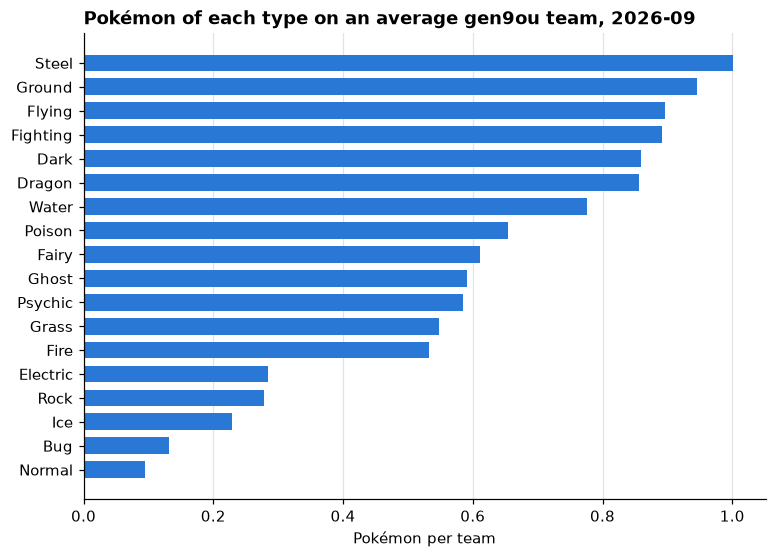

In [6]:
type_counts = (
    top_ou.unpivot(on=["type1", "type2"], index="usage_pct", value_name="type")
    .drop_nulls("type")
    .group_by("type")
    .agg((pl.col("usage_pct").sum() / 100).alias("per_team"))
    .sort("per_team")
)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(type_counts["type"], type_counts["per_team"], height=0.7)
ax.set_title(f"Pokémon of each type on an average {latest_ou['format']} team, {latest_month}")
ax.set_xlabel("Pokémon per team")
ax.grid(axis="y", visible=False)
plt.show()

## One Pokémon over time

Filter `usage` on a series and a `pokemon_id` to get a time series. Here, the Pokémon ranked first in the table above, over the whole life of its series.

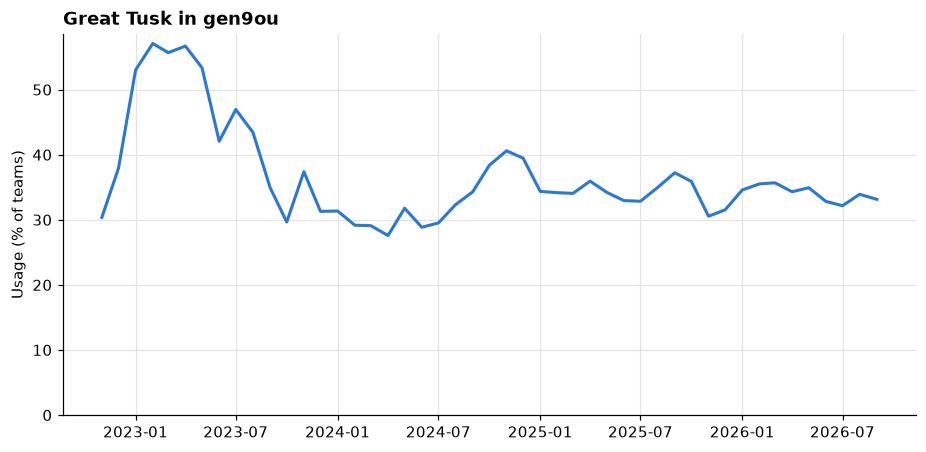

Rank 1 in 36 of 47 months


In [7]:
def with_series(usage_df):
    return usage_df.join(formats.select("month", "format", "lite_series", "gen"), on=["month", "format"]).with_columns(
        pl.col("month").str.to_date("%Y-%m").alias("month_start")
    )


leader = top_ou.row(0, named=True)
leader_usage = (
    with_series(usage)
    .filter((pl.col("lite_series") == latest_ou["lite_series"]) & (pl.col("pokemon_id") == leader["pokemon_id"]))
    .sort("month")
)

fig, ax = plt.subplots()
ax.plot(leader_usage["month_start"], leader_usage["usage_pct"])
ax.set_title(f"{leader['name']} in {latest_ou['lite_series']}")
ax.set_ylabel("Usage (% of teams)")
ax.set_ylim(0)
plt.show()

print(f"Rank 1 in {(leader_usage['rank'] == 1).sum()} of {leader_usage.height} months")

## A series across generations

`ubers` follows the Ubers tier from one generation to the next. The chart sums usage by `base_species`, for a reason worth knowing: until 2015-10 Smogon counted a Mega Evolution or Primal Reversion under its base Pokémon, and from 2015-11 on each one has its own `pokemon_id` (`groudon` and `groudonprimal`). Grouping by `base_species` keeps the lines continuous.

The six species shown are the ones with the highest average usage over the months of the series. Dotted lines mark the first month of each generation in the series, and a line breaks in the months where the species has no usage row.

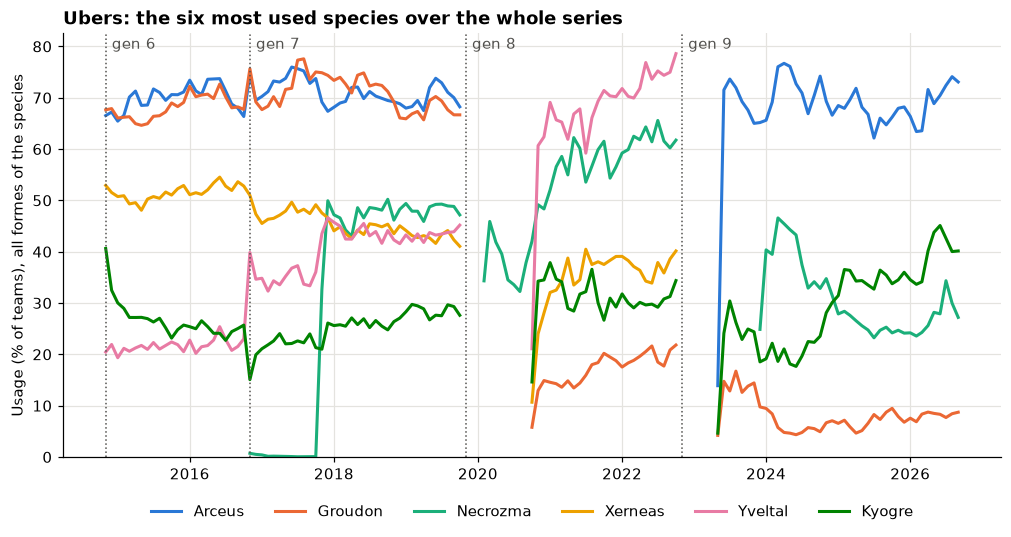

In [8]:
ubers_usage = (
    with_series(usage)
    .filter(pl.col("lite_series") == "ubers")
    .join(pokemon.select("pokemon_id", "base_species"), on="pokemon_id")
    .group_by("month_start", "base_species")
    .agg(pl.col("usage_pct").sum())
    .sort("month_start")
)
ubers_months = ubers_usage["month_start"].n_unique()
ubers_kings = (
    ubers_usage.group_by("base_species")
    .agg((pl.col("usage_pct").sum() / ubers_months).alias("mean_usage"))
    .sort("mean_usage", "base_species", descending=[True, False])
    .head(6)["base_species"]
)

fig, ax = plt.subplots(figsize=(11, 5))
# One column per species: a month without a row becomes a null, and the line breaks there.
kings_by_month = (
    ubers_usage.filter(pl.col("base_species").is_in(ubers_kings.implode()))
    .pivot(on="base_species", index="month_start", values="usage_pct")
    .join(ubers_usage.select("month_start").unique(), on="month_start", how="right")
    .sort("month_start")
)
for species in ubers_kings:
    ax.plot(kings_by_month["month_start"], kings_by_month[species], label=species)

gen_starts = (
    formats.filter(pl.col("lite_series") == "ubers")
    .group_by("gen")
    .agg(pl.col("month").min().str.to_date("%Y-%m").alias("month_start"))
    .sort("gen")
)
for gen, month_start in gen_starts.iter_rows():
    ax.axvline(month_start, color="#52514e", linewidth=1, linestyle=":")
    ax.annotate(
        f"gen {gen}",
        (month_start, 1),
        xycoords=("data", "axes fraction"),
        xytext=(4, -10),
        textcoords="offset points",
        color="#52514e",
    )

ax.set_title("Ubers: the six most used species over the whole series")
ax.set_ylabel("Usage (% of teams), all formes of the species")
ax.set_ylim(0)
ax.legend(ncols=6, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.show()

## How a Pokémon is played

`abilities`, `items` and `moves` give, for one Pokémon in one month and format, the share of its sets using each option. Names are Showdown ids (`choicescarf`, `uturn`). Options under 0.1 % are left out. A Pokémon has four move slots, so `moves.pct` adds up to about 400; an empty slot is the move `""`, dropped here.

These tables are the big ones, so filter the lazy scan before collecting.

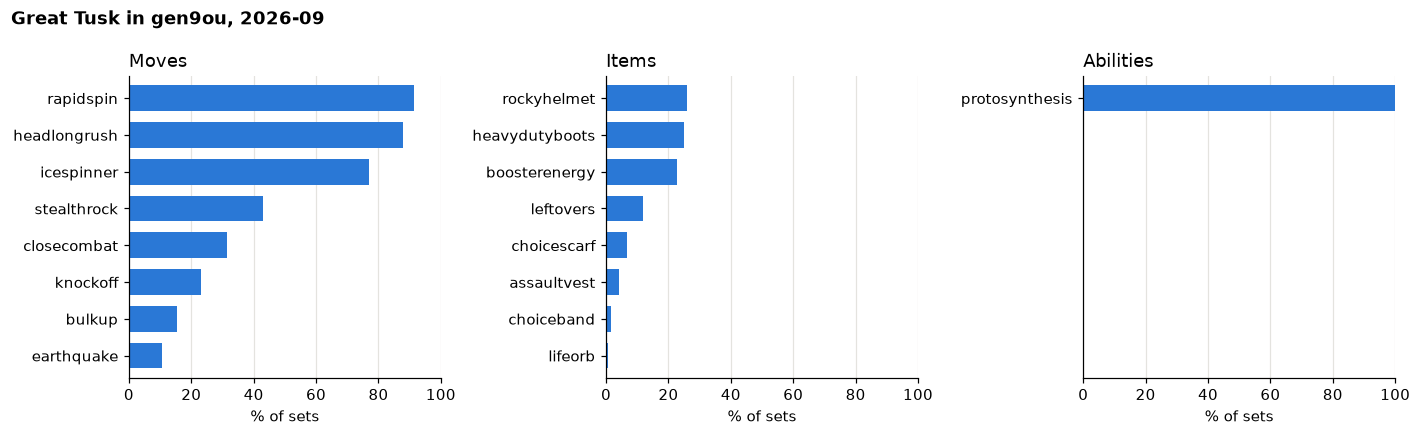

In [9]:
def top_choices(detail_lf, column):
    return (
        detail_lf.filter(
            (pl.col("month") == latest_month)
            & (pl.col("format") == latest_ou["format"])
            & (pl.col("pokemon_id") == leader["pokemon_id"])
            & (pl.col(column) != "")
        )
        .sort("pct", descending=True)
        .head(8)
        .collect()
    )


fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True)
panels = [(moves, "move", "Moves"), (items, "item", "Items"), (abilities, "ability", "Abilities")]
for ax, (detail_lf, column, title) in zip(axes, panels, strict=True):
    choices = top_choices(detail_lf, column)
    ax.barh(choices[column], choices["pct"], height=0.7)
    ax.set_ylim(7.6, -0.6)
    ax.set_title(title, fontweight="normal")
    ax.set_xlabel("% of sets")
    ax.set_xlim(0, 100)
    ax.grid(axis="y", visible=False)
fig.suptitle(f"{leader['name']} in {latest_ou['format']}, {latest_month}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Only Pokémon that Smogon's detailed files cover have rows here: anything under about 0.01 % usage is ranked in `usage` but has no abilities, items or moves.

In [10]:
detailed = abilities.select("month", "format", "pokemon_id").unique().collect()
undetailed = usage.join(detailed, on=["month", "format", "pokemon_id"], how="anti")
print(f"{undetailed.height / usage.height:.0%} of usage rows have no detail rows")
print(f"their highest usage_pct is {undetailed['usage_pct'].max()}")

51% of usage rows have no detail rows
their highest usage_pct is 0.00999


## How much each series is played

`formats.battles` is the number of battles behind each month of statistics. The scale is logarithmic and shared by all panels. Check it before reading too much into a ranking: some months of the old generations rest on a few hundred battles.

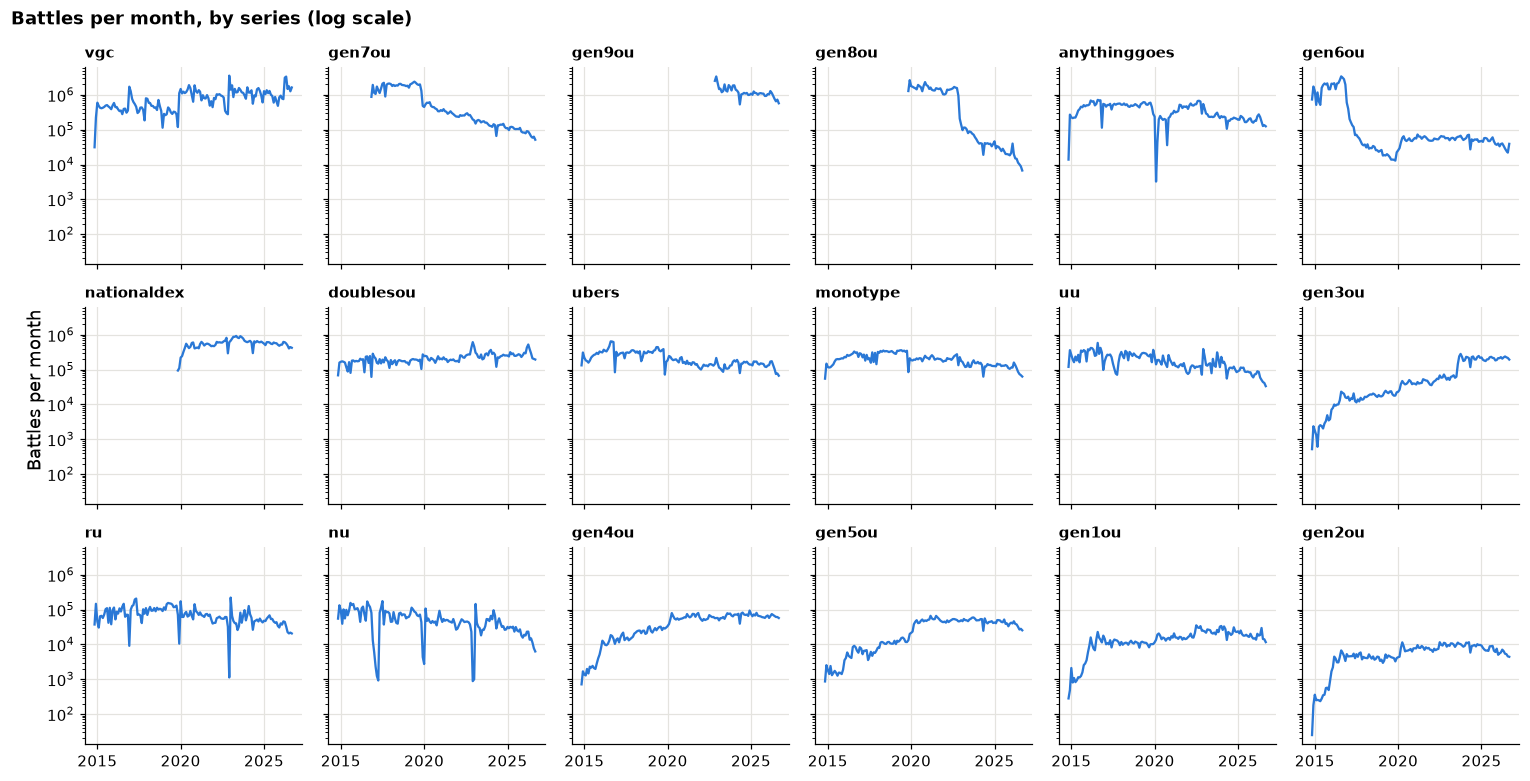

In [11]:
series_battles = formats.with_columns(pl.col("month").str.to_date("%Y-%m").alias("month_start")).sort("month")
series_order = (
    series_battles.group_by("lite_series")
    .agg(pl.col("battles").sum())
    .sort("battles", "lite_series", descending=[True, False])["lite_series"]
)

n_cols = 6
n_rows = -(-len(series_order) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 2.4 * n_rows), sharex=True, sharey=True, squeeze=False)
for ax, series in zip(axes.flat[: len(series_order)], series_order, strict=True):
    one_series = series_battles.filter((pl.col("lite_series") == series) & (pl.col("battles") > 0))
    ax.plot(one_series["month_start"], one_series["battles"], linewidth=1.5)
    ax.set_title(series, fontsize=10)
    ax.set_yscale("log")
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in axes.flat[len(series_order) :]:
    ax.set_visible(False)
fig.suptitle("Battles per month, by series (log scale)", x=0.01, ha="left", fontweight="bold")
fig.supylabel("Battles per month")
fig.tight_layout()
plt.show()

## Going further

A few things to keep in mind when you build on this:

- one cutoff per month and format (`formats.standard_cutoff`), so no cutoff filter is needed, but that cutoff is 1695 for some formats and 1630 for the others;
- Mega Evolutions and Primal Reversions only have their own rows from 2015-11 on;
- `tera_types` only has rows from 2024-08 on, when Smogon started publishing them.

The Lite leaves a lot out. The **Smogon Usage Stats: Complete** datasets (one per year) have every format (including one per Monotype type), all four rating cutoffs, and the tables that are not here: EV spreads and natures, teammates, checks and counters, leads, and team styles. The same package reads them with `ss.load(table, years=..., formats=..., cutoffs=...)`.

Source: [smogon.com/stats](https://www.smogon.com/stats/); Pokémon names, types and base stats come from [Pokémon Showdown](https://github.com/smogon/pokemon-showdown).